In [1]:
from google.colab import userdata
import os

os.environ["CARTO_API_KEY"] = userdata.get("CARTO_API_KEY")

In [14]:
!git clone https://github.com/talalhaider9/LucidMA2.0.git
%cd LucidMA2.0
!pip install -q -e .

Cloning into 'LucidMA2.0'...
remote: Enumerating objects: 141, done.
remote: Counting objects: 100% (141/141), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 141 (delta 70), reused 114 (delta 46), pack-reused 0 (from 0)
Receiving objects: 100% (141/141), 722.13 KiB | 24.90 MiB/s, done.
Resolving deltas: 100% (70/70), done.
/content/LucidMA2.0/LucidMA2.0
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for lucid-ma (pyproject.toml) ... done


In [3]:
!python -m lucid_ma --query "theft from motor vehicle" --limit 50000

Analyzing query: theft from motor vehicle
Fetching Chicago crime data...
Cleaned data: 50,000 records
Knowledge graph: 70,101 nodes, 799,701 edges
modules.json: 100% 349/349 [00:00<00:00, 1.79MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 612kB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 29.7MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 255kB/s]
config.json: 100% 612/612 [00:00<00:00, 3.37MB/s]

model.safetensors: downloading bytes:  83% 75.6M/90.9M [00:01<00:00, 76.2MB/s, 5.15MB/s  ]
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:01<00:00, 50.4MB/s, 8.08MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:01<00:00, 53.9MB/s, 8.75MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 4406.41it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 2.12MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 78.4MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 115MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 743kB/s]
config

In [4]:
!pip install -q -e ".[agents]"

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for lucid-ma (pyproject.toml) ... done


In [5]:
!apt-get update -qq
!apt-get install -y -qq zstd
!curl -fsSL https://ollama.com/install.sh | sh
!which ollama
!ollama --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package zstd.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../zstd_1.5.5+dfsg2-2build1.1_amd64.deb ...
Unpacking zstd (1.5.5+dfsg2-2build1.1) ...
Setting up zstd (1.5.5+dfsg2-2build1.1) ...
Processing triggers for man-db (2.12.0-4build2) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
/usr/local/bin/ollama


In [6]:
!nohup ollama serve > /tmp/ollama.log 2>&1 &
!sleep 8
!ollama list

NAME    ID    SIZE    MODIFIED 


In [7]:
!ollama pull deepseek-r1:8b

In [13]:
!ollama list

NAME              ID              SIZE      MODIFIED       
deepseek-r1:8b    6995872bfe4c    5.2 GB    23 minutes ago    


In [9]:
%pip install -q "ag2[openai]"

In [10]:
import shutil
import subprocess
import time
import requests

ollama_path = shutil.which("ollama")
assert ollama_path, "Ollama installation failed or the executable is not on PATH"

ollama_log = open("/tmp/ollama.log", "w")
ollama_process = subprocess.Popen(
    [ollama_path, "serve"],
    stdout=ollama_log,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

for _ in range(30):
    try:
        if requests.get("http://127.0.0.1:11434/api/tags", timeout=2).ok:
            print("Ollama is ready")
            break
    except requests.RequestException:
        pass
    time.sleep(2)
else:
    raise RuntimeError("Ollama did not start; inspect /tmp/ollama.log")

Ollama is ready


In [11]:
!pip install autogen

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 73.8 MB/s  0:00:00


In [16]:
%cd /content/LucidMA2.0
!python -m lucid_ma --query "tell me about theft cases" --limit 30000 --agents

/content/LucidMA2.0
Analyzing query: tell me about theft cases
Fetching Chicago crime data...
Cleaned data: 30,000 records
Knowledge graph: 45,418 nodes, 479,814 edges
Loading weights: 100% 103/103 [00:00<00:00, 4110.89it/s]
--- VERIFIED CHICAGO CRIME PROFILE ---
Crime type: THEFT
Records: 6459 (6451 have coordinate data)
Coverage: 2026-09-08T16:17:00+00:00 to 2026-10-25T00:00:00+00:00
Peak observed hour: 12:00
Arrest rate: 8.1% | Domestic-related rate: 5.1%
Top descriptions: $500 AND UNDER (1889); RETAIL THEFT (1675); OVER $500 (1470); THEFT FROM MOTOR VEHICLE (755); FROM BUILDING (421)
Top location types: STREET (1232); APARTMENT (926); SMALL RETAIL STORE (744); DEPARTMENT STORE (549); RESIDENCE (444)
Top community areas by reported count: 8 (574); 32 (409); 28 (371); 6 (258); 22 (230)
Top districts by reported count: 018 (658); 001 (577); 019 (553); 012 (431); 014 (358)
Top coarse hotspot cells (latitude/longitude grid, not addresses): Lat:41.882_Lon:-87.628 (79); Lat:41.804_Lon:-87

In [17]:
print(open("outputs/analysis.md", encoding="utf-8").read())

# Theft analysis

Query: `tell me about theft cases`

- Records analyzed: 6459
- Records with coordinates: 6451
- Coverage: 2026-09-08T16:17:00+00:00 to 2026-10-25T00:00:00+00:00
- Peak observed hour: 12:00
- Arrest rate: 8.1%
- Domestic-related rate: 5.1%

## Top descriptions

- $500 AND UNDER: 1889
- RETAIL THEFT: 1675
- OVER $500: 1470
- THEFT FROM MOTOR VEHICLE: 755
- FROM BUILDING: 421
- POCKET-PICKING: 184
- ATTEMPT THEFT: 41
- PURSE-SNATCHING: 21
- DELIVERY CONTAINER THEFT: 3

## Top location types

- STREET: 1232
- APARTMENT: 926
- SMALL RETAIL STORE: 744
- DEPARTMENT STORE: 549
- RESIDENCE: 444
- SIDEWALK: 282
- RESIDENCE - PORCH / HALLWAY: 230
- RESTAURANT: 213
- GROCERY FOOD STORE: 184
- PARKING LOT / GARAGE (NON RESIDENTIAL): 181

## Top community areas

- 8: 574
- 32: 409
- 28: 371
- 6: 258
- 22: 230
- 24: 224
- 3: 198
- 25: 171
- 7: 170
- 43: 166

## Top districts

- 018: 658
- 001: 577
- 019: 553
- 012: 431
- 014: 358
- 002: 339
- 008: 338
- 025: 299
- 006: 297
- 009: 29

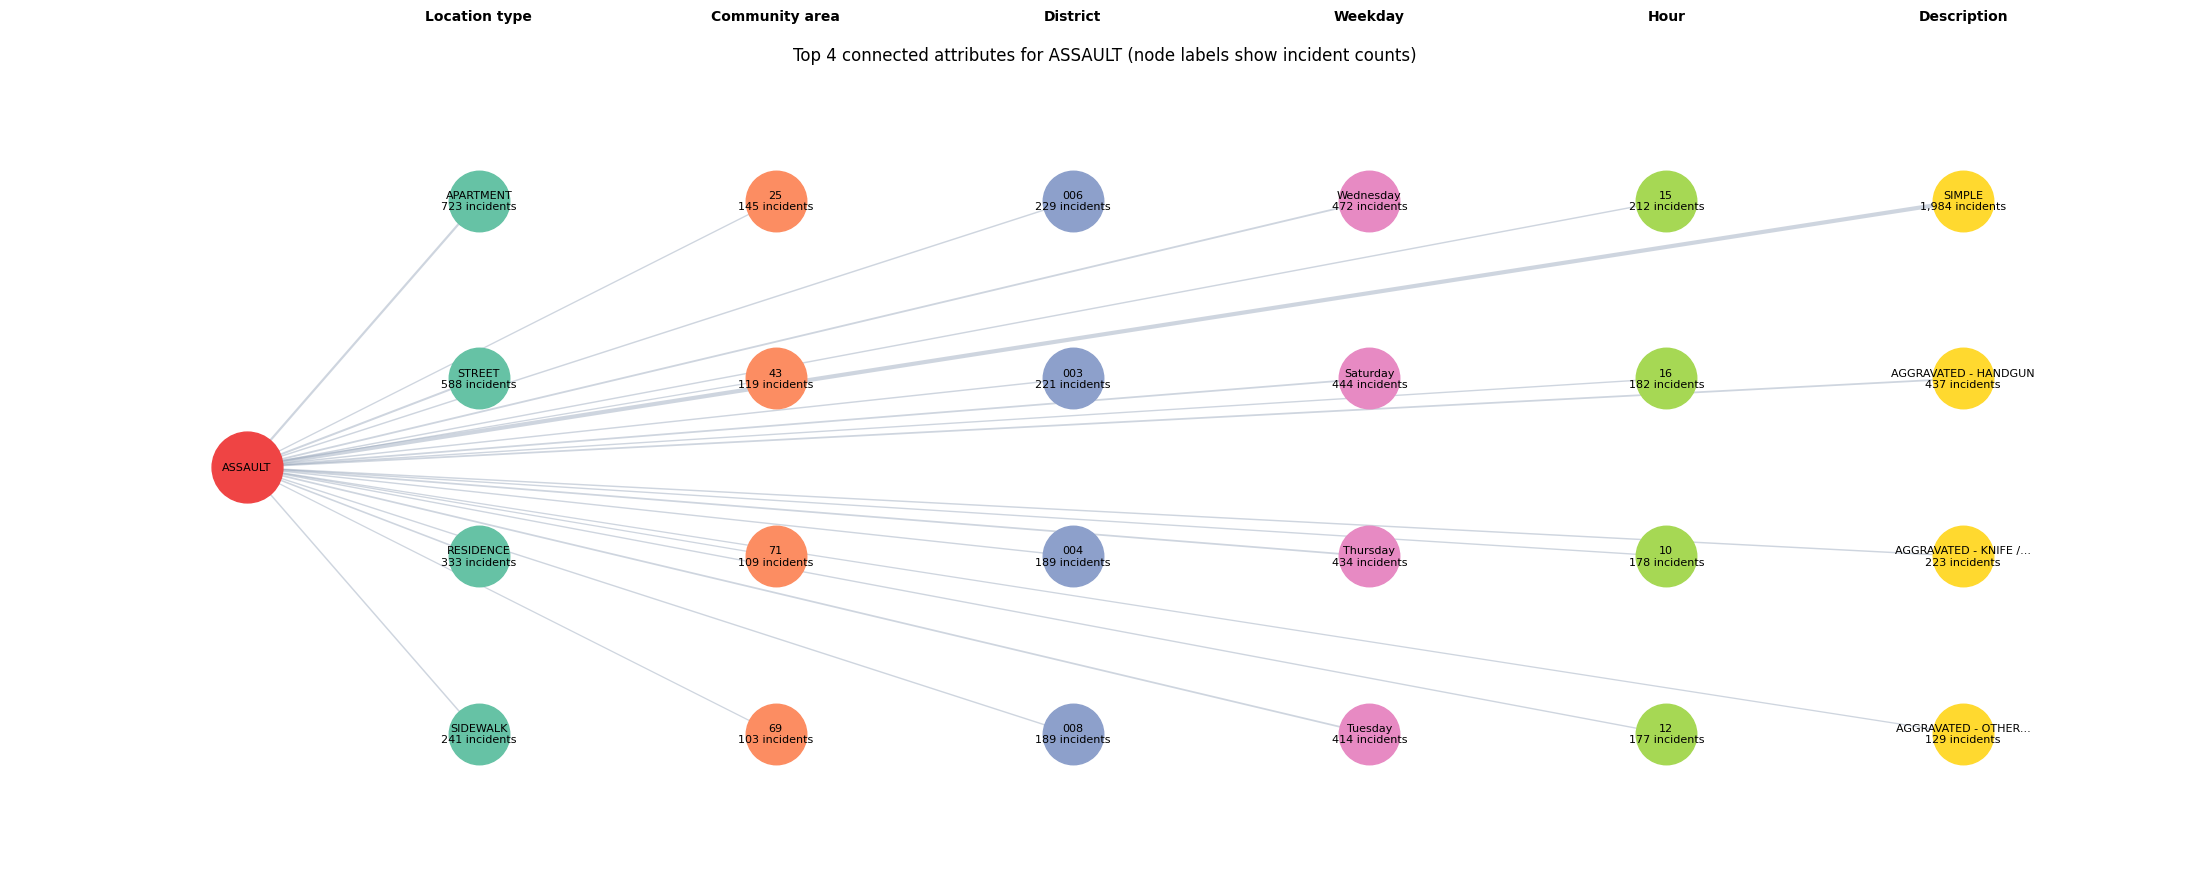

In [18]:
import sys
sys.path.insert(0, "/content/LucidMA2.0/src")

from collections import Counter
import textwrap

from lucid_ma.data import fetch_crime_data, build_crime_graph
import networkx as nx
import matplotlib.pyplot as plt

df = fetch_crime_data()
graph = build_crime_graph(df)

crime_type = "ASSAULT"
crime_node = f"crime:{crime_type}"

if crime_node not in graph:
    raise ValueError(f"No incidents found for crime type {crime_type!r}.")

# The crime node connects to incidents; each incident connects to its attributes.
incident_nodes = [
    node for node in graph.neighbors(crime_node)
    if graph.nodes[node].get("kind") == "incident"
]
attribute_counts = Counter()
for incident_node in incident_nodes:
    for attribute_node in graph.neighbors(incident_node):
        kind = graph.nodes[attribute_node].get("kind")
        label = graph.nodes[attribute_node].get("label")
        if kind and kind != "incident" and label is not None:
            attribute_counts[(kind, str(label))] += 1

dimensions = [
    ("location", "Location type"),
    ("community", "Community area"),
    ("district", "District"),
    ("weekday", "Weekday"),
    ("hour", "Hour"),
    ("description", "Description"),
]
top_n = 4
summary = nx.Graph()
summary.add_node(crime_node, kind="crime", label=crime_type)
groups = []
for kind, title in dimensions:
    values = sorted(
        ((label, count) for (value_kind, label), count in attribute_counts.items() if value_kind == kind),
        key=lambda item: (-item[1], item[0]),
    )[:top_n]
    if values:
        groups.append((kind, title, values))
        for value, count in values:
            node = f"attribute:{kind}:{value}"
            summary.add_node(node, kind=kind, label=value, count=count)
            summary.add_edge(crime_node, node, weight=count)

if not groups:
    raise ValueError(f"No connected attributes found for crime type {crime_type!r}.")

# Fixed columns by attribute type keep the plot readable and comparable.
positions = {crime_node: (-2.5, 0)}
for column, (_, _, values) in enumerate(groups):
    for row, (value, _) in enumerate(values):
        node = f"attribute:{groups[column][0]}:{value}"
        positions[node] = (column * 3.2, (len(values) - 1) / 2 - row)

labels = {crime_node: crime_type}
for node, data in summary.nodes(data=True):
    if node != crime_node:
        value = textwrap.shorten(data["label"], width=26, placeholder="...")
        labels[node] = f"{value}\n{data['count']:,} incidents"

max_count = max(data["weight"] for _, _, data in summary.edges(data=True))
edge_widths = [0.8 + 2.2 * data["weight"] / max_count for _, _, data in summary.edges(data=True)]
figure, axis = plt.subplots(figsize=(max(16, 3.2 * len(groups) + 3), max(7, 2.2 * top_n)))
nx.draw_networkx_edges(
    summary, positions, ax=axis, width=edge_widths, edge_color="#94a3b8", alpha=0.45
)
nx.draw_networkx_nodes(
    summary, positions, nodelist=[crime_node], node_color="#ef4444", node_size=2600, ax=axis
)
palette = plt.get_cmap("Set2")
for index, (kind, title, _) in enumerate(groups):
    nodes = [node for node, data in summary.nodes(data=True) if data.get("kind") == kind]
    nx.draw_networkx_nodes(
        summary, positions, nodelist=nodes, node_color=[palette(index % 8)], node_size=1900, ax=axis
    )
    axis.text(index * 3.2, top_n / 2 + 0.5, title, ha="center", va="bottom", fontsize=10, fontweight="bold")

nx.draw_networkx_labels(summary, positions, labels=labels, font_size=8, ax=axis)
axis.set_title(f"Top {top_n} connected attributes for {crime_type} (node labels show incident counts)")
axis.margins(x=0.08, y=0.18)
axis.axis("off")
figure.tight_layout()
plt.show()